In [1]:
import numpy as np
import torch
torch.manual_seed(42)
np.random.seed(42)
# embdata=np.load('embdata.npy')a
# ydata_norm=np.load('ydata_norm.npy')
ydata=np.load('ydata.npy')
sampled_point=np.load('sp.npy')
ydata.shape

(93340, 40, 240)

In [ ]:
sp5index=np.array([3,5,7])
# sp3index=np.array([1,5,9])-1
sp5=sampled_point[:,sp5index]
# sp3=sampled_point[:,sp3index]

def normalize(x,x_max,x_min):
    if x_max==x_min:
        return np.ones_like(x)*0.5
    return (x-x_min)/(x_max-x_min)*2-1

def denormalize(x,x_max,x_min):
    drange=x_max-x_min
    return (x+1)/2*drange+x_min

sp5max=np.max(sp5,axis=1)
sp5min=np.min(sp5,axis=1)

sp5max_max=sp5max.max()
sp5max_min=sp5max.min()
sp5min_max=sp5min.max()
sp5min_min=sp5min.min()

sp5max_n=normalize(sp5max,sp5max_max,sp5max_min)
sp5min_n=normalize(sp5min,sp5min_max,sp5min_min)

sp5n=normalize(sp5,sp5max.reshape(-1,1),sp5min.reshape(-1,1))

embdata=np.concatenate((sp5n,sp5max_n.reshape(-1,1),sp5min_n.reshape(-1,1)),axis=1)
ydata_norm=normalize(ydata,sp5max.reshape(-1,1,1),sp5min.reshape(-1,1,1))

# embdata.shape,ydata_norm.shape

/tmp/ipykernel_127304/4217576809.py:9: RuntimeWarning: invalid value encountered in divide
  return (x-x_min)/(x_max-x_min)*2-1
/tmp/ipykernel_127304/4217576809.py:9: RuntimeWarning: divide by zero encountered in divide
  return (x-x_min)/(x_max-x_min)*2-1


In [3]:
sp5max_max,sp5max_min,sp5min_max,sp5min_min

(327.01816, 288.14395, 324.8986, 288.13727)

In [5]:
def find_same_min_max_rows_2(data):
    """
    方法2：使用np.all判断所有元素是否相等
    """
    # 方法2.1：直接检查所有元素是否与第一个元素相等
    first_col = data[:, 0:1]  # 保持维度为(n, 1)
    same_rows_mask = np.all(data == first_col, axis=1)
    
    # 方法2.2：或者检查每行的标准差是否为0
    # same_rows_mask = np.std(data, axis=1) == 0
    
    return np.where(same_rows_mask)[0]

# 执行
same_rows_2 = find_same_min_max_rows_2(sp5)
print(f"\n方法2找到 {len(same_rows_2)} 行")
# print(f"两种方法结果是否相同: {np.array_equal(same_rows, same_rows_2)}")


方法2找到 4 行


In [7]:
import numpy as np

# 创建示例数据（实际使用时替换为你的数据）
# data = np.load('your_data.npy')  # 加载你的数据
# data = np.random.rand(93340, 3)  # 示例数据

# # 为了测试，手动创建一些所有元素相等的行
# data[100] = [5.0, 5.0, 5.0]      # 第100行：全相等
# data[5000] = [3.0, 3.0, 3.0]     # 第5000行：全相等
# data[90000] = [7.0, 7.0, 7.0]    # 第90000行：全相等

data=sp5
# 找出每行最大值和最小值相同的行
row_max = data.max(axis=1)  # 每行最大值
row_min = data.min(axis=1)  # 每行最小值

# 找出最大值等于最小值的行索引
equal_rows = np.where(row_max == row_min)[0]

print(f"总行数: {len(data)}")
print(f"最大值等于最小值的行数: {len(equal_rows)}")
print(f"行索引: {equal_rows}")
print(f"对应的值: {data[equal_rows]}")

# 验证
if len(equal_rows) > 0:
    print("\n验证:")
    for idx in equal_rows[:5]:  # 只显示前5个
        print(f"  行 {idx}: {data[idx]}, max={data[idx].max()}, min={data[idx].min()}")

总行数: 93340
最大值等于最小值的行数: 4
行索引: [ 5561 38641 72743 74543]
对应的值: [[288.14978 288.14978 288.14978]
 [308.1498  308.1498  308.1498 ]
 [298.1498  298.1498  298.1498 ]
 [308.14978 308.14978 308.14978]]

验证:
  行 5561: [288.14978 288.14978 288.14978], max=288.1497802734375, min=288.1497802734375
  行 38641: [308.1498 308.1498 308.1498], max=308.1498107910156, min=308.1498107910156
  行 72743: [298.1498 298.1498 298.1498], max=298.1498107910156, min=298.1498107910156
  行 74543: [308.14978 308.14978 308.14978], max=308.1497802734375, min=308.1497802734375


In [5]:
sp5max_n.shape,sp5min_n.shape

((93340,), (93340,))

In [6]:
sp5n=normalize(sp5,sp5max.reshape(-1,1),sp5min.reshape(-1,1))

In [8]:
sp5n[:5]

array([[-0.21808875, -1.        , -0.09249145, -0.28873718,  1.        ],
       [ 0.8048384 , -1.        ,  0.5049521 ,  1.        , -0.7228446 ],
       [ 0.8465564 , -1.        ,  0.50757575,  1.        , -0.7549587 ],
       [ 0.8283206 , -1.        ,  0.49643064,  1.        , -0.7963722 ],
       [ 0.8365555 , -1.        ,  0.48526597,  1.        , -0.8676377 ]],
      dtype=float32)

In [3]:
array=np.arange(0,ydata_norm.shape[0])
index=np.random.choice(array,10000,replace=False)

v_ydata=ydata_norm[index]
v_emb=embdata[index]
t_ydata=np.delete(ydata_norm,index,0)
t_emb=np.delete(embdata,index,0)

from torch.utils.data import Dataset,DataLoader
class MyDataset(Dataset):
    def __init__(self,embdata,ydata):
        self.embdata=embdata
        self.ydata=ydata
    def __len__(self):
        return len(self.embdata)
    def __getitem__(self,idx):
        return self.embdata[idx],self.ydata[idx]

train_dataset=MyDataset(t_emb,t_ydata)
val_dataset=MyDataset(v_emb,v_ydata)
train_loader=DataLoader(train_dataset,batch_size=32)
val_loader=DataLoader(val_dataset,batch_size=50)

In [4]:
import torch
import torch.nn as nn
from tqdm import tqdm
from diffusion_model import DiffusionModel
# device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
device="cuda:1"

diffusion=DiffusionModel(
    image_size=(40,240),
    channels=1,
    cond_dim=11,
    timesteps=1000,
    device=device
)

diffusion.load('final_model.pt')

# epochs=5
# optimizer=torch.optim.AdamW(diffusion.model.parameters(),lr=1e-4,weight_decay=1e-4)
# scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=epochs,eta_min=1e-6)

# for epoch in range(epochs):
#     diffusion.model.train()
#     epoch_loss=0
#     progress_bar=tqdm(train_loader,desc=f"Epoch {epoch+1}/{epochs}")
#     for eb,yb in progress_bar:
#         eb=eb.to(device)
#         yb=yb.unsqueeze(1).to(device)
#         loss=diffusion.train_step(yb,eb,optimizer)
#         epoch_loss+=loss
#         progress_bar.set_postfix({'loss':loss})
#     avg_loss=epoch_loss/len(train_loader)
#     scheduler.step()

# diffusion.save('final_model.pt')

/home/wbl/thermal/openfoam/daopian/model_training/claudecode/diffusion_model.py:466: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(path, map_location

Model loaded from final_model.pt


In [ ]:
from tqdm import tqdm
diffusion.model.eval()
y_true=np.empty((0,40,240))
y_pred=np.empty((0,40,240))
x_in=np.empty((0,11))
for veb,vyb in tqdm(val_loader):
    x_in=np.concatenate((x_in,veb.numpy()),axis=0)
    y_true=np.concatenate((y_true,vyb.numpy()),axis=0)
    veb=veb.to(device)
    # vyb=vyb.unsqueeze(1).to(device)
    sample=diffusion.generate(veb, num_samples=vyb.size(0))
    y_pred=np.concatenate((y_pred,sample[:,0,:,:]),axis=0)

 10%|█         | 21/200 [1:28:46<12:36:40, 253.63s/it]


KeyboardInterrupt: 

In [ ]:

x_in.shape, y_true.shape, y_pred.shape

((250, 11), (250, 40, 240), (200, 40, 240))

In [ ]:
spmax_vector=denormalize(x_in[:,9],spmax_max,spmax_min).reshape(-1,1,1)
spmin_vector=denormalize(x_in[:,10],spmin_max,spmin_min).reshape(-1,1,1)

true=denormalize(y_true,spmax_vector,spmin_vector)
pred=denormalize(y_pred,spmax_vector,spmin_vector)
spmax_vector.shape,spmin_vector.shape,true.shape, pred.shape

((250, 1, 1), (250, 1, 1), (250, 40, 240))

In [ ]:
def calculate_rmse(matrix1, matrix2):
    error = matrix1 - matrix2    
    # 计算均方误差 (MSE)
    mse = np.mean(error ** 2)    
    # 计算均方根误差 (RMSE)
    rmse = np.sqrt(mse)    
    return rmse
sp9_rmse=[]
for i in range(true.shape[0]):
    rmse=calculate_rmse(true[i],pred[i])
    sp9_rmse.append(rmse)

np.save('sp9_rmse.npy', np.array(sp9_rmse))
np.array(sp9_rmse).shape

0.0

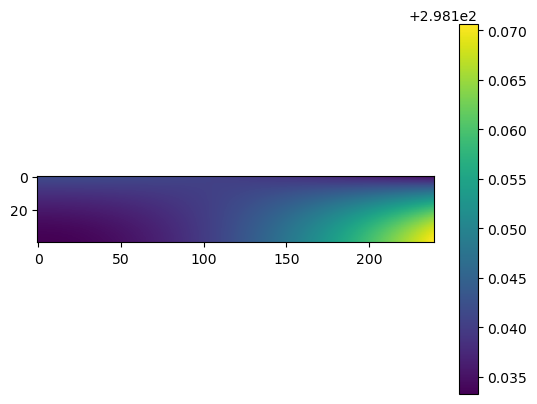

In [ ]:
# import matplotlib.pyplot as plt
# plt.imshow(true[i])
# plt.colorbar()


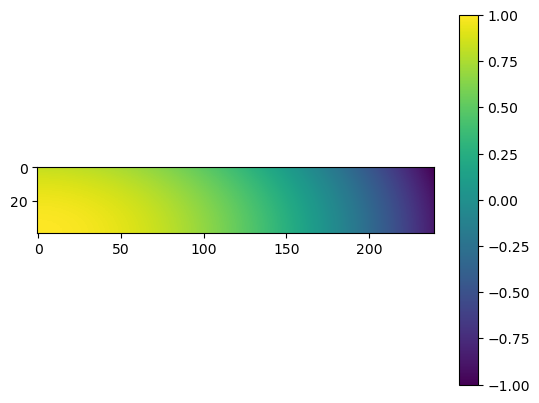

In [ ]:
# plt.imshow(vyb[8])
# plt.colorbar()

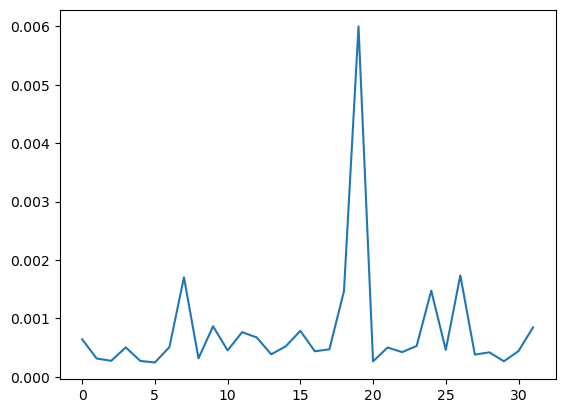

In [ ]:


# rmselist=[]
# for i in range(sample.shape[0]):
#     rmse=calculate_rmse(sample[i][0],vyb[i].numpy())
#     rmselist.append(rmse)
# plt.plot(rmselist)

In [ ]:


# spmax=denormalize(veb.cpu()[:,9],spmax_max,spmax_min)
# spmin=denormalize(veb.cpu()[:,10],spmin_max,spmin_min)
# spmax[8], spmin[8]

(tensor(301.2418), tensor(300.5418))

In [ ]:
# pre=denormalize(sample[8][0],spmax_max,spmax_min)
# tru=denormalize(vyb[8].numpy(),spmax_max,spmax_min)
# calculate_rmse(pre, tru)

0.0061549516